Урок в прозе: https://proproprogs.ru/nn_pytorch/pytorch-l2-regulyarizator-i-dropout

neuro_net_24_L2.py: https://github.com/selfedu-rus/neuro-pytorch

neuro_net_24_Dropout.py: https://github.com/selfedu-rus/neuro-pytorch

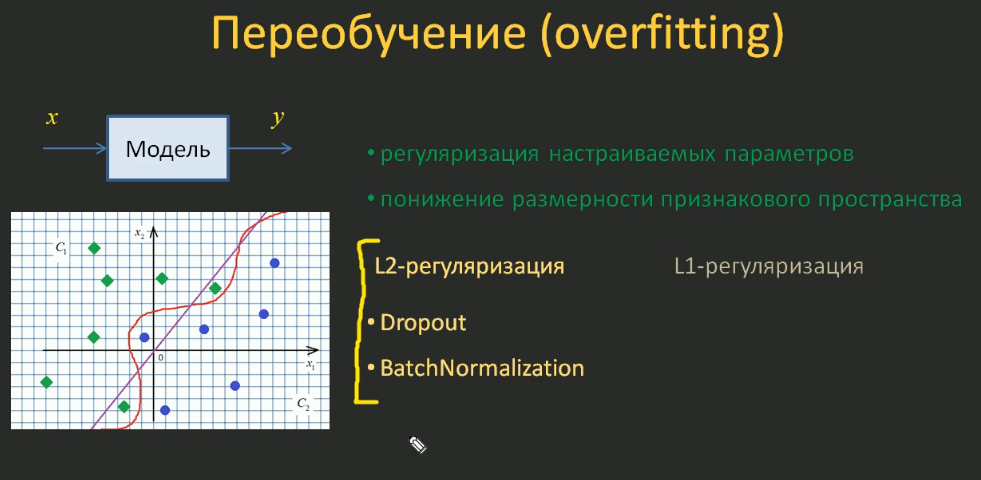

L1-регуляризацию в основном не используют, так как она склонна занулять веса

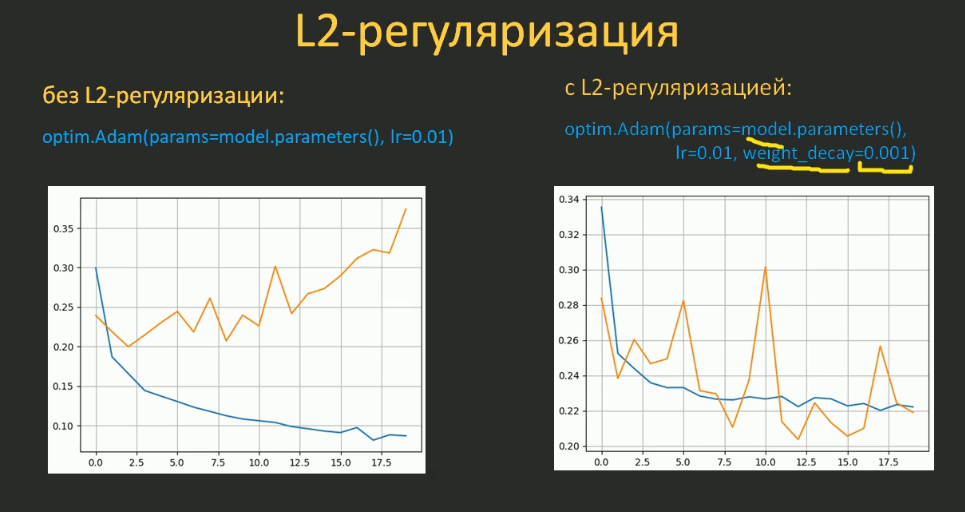

Обычно сначала (сразу) пробуют добавить L2-регуляризацию, а потом уже (если наблюдается переобучение, проявляющееся в расхождении кривых обучения и валидации) экспериментируют с уменьшением числа нейронов и дропаутами 

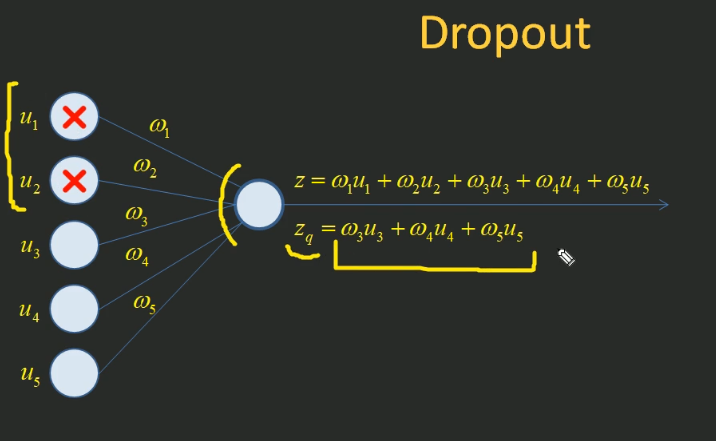

Dropout снижает переобучение путем универсализации нейронов. но так как влияние предыдущего слоя на последующий падает, то нейроны домножают на величину, обратную числу отсуттвующих нейронов

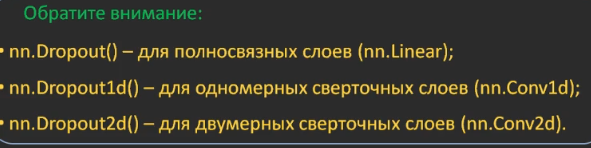

 | loss_mean=0.310, Q_val=0.249


 | loss_mean=0.245, Q_val=0.262


 | loss_mean=0.231, Q_val=0.292


 | loss_mean=0.217, Q_val=0.195


 | loss_mean=0.221, Q_val=0.206


 | loss_mean=0.223, Q_val=0.214


... (10 outputs left out)

 | loss_mean=0.213, Q_val=0.218


 | loss_mean=0.221, Q_val=0.200


 | loss_mean=0.212, Q_val=0.237


 | loss_mean=0.214, Q_val=0.240
0.9322


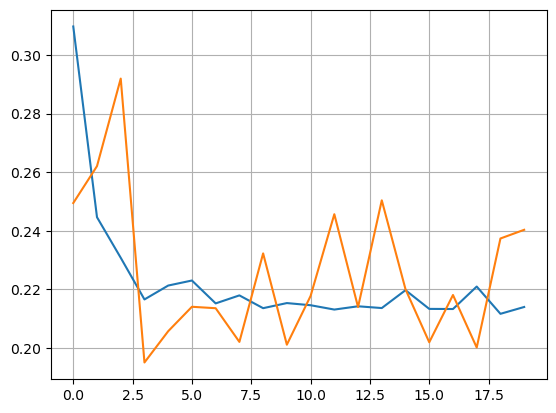

In [2]:
import matplotlib.pyplot as plt

import torch
import torch.utils.data as data
import torchvision.transforms.v2 as tfs
import torchvision
import torch.nn as nn
import torch.optim as optim
from tqdm import tqdm
from torchvision.datasets import ImageFolder


class RavelTransform(nn.Module):
    def forward(self, item):
        return item.ravel()


class DigitNN(nn.Module):
    def __init__(self, input_dim, num_hidden, output_dim):
        super().__init__()
        self.layer1 = nn.Linear(input_dim, num_hidden)
        self.layer2 = nn.Linear(num_hidden, output_dim)

    def forward(self, x):
        x = self.layer1(x)
        x = nn.functional.relu(x)
        x = self.layer2(x)
        return x


model = DigitNN(28 * 28, 128, 10)

transforms = tfs.Compose([tfs.ToImage(),  tfs.Grayscale(),
                          tfs.ToDtype(torch.float32, scale=True),
                          RavelTransform(),
                          ])

dataset_mnist = torchvision.datasets.MNIST(r'C:\datasets\mnist', download=True, train=True, transform=transforms)
d_train, d_val = data.random_split(dataset_mnist, [0.7, 0.3])
train_data = data.DataLoader(d_train, batch_size=32, shuffle=True)
train_data_val = data.DataLoader(d_val, batch_size=32, shuffle=False)


optimizer = optim.Adam(params=model.parameters(), lr=0.01, weight_decay=0.001)
loss_function = nn.CrossEntropyLoss()
epochs = 20

loss_lst_val = [] # список значений потерь при валидации
loss_lst = [] # список значений потерь при обучении

for _e in range(epochs):
    model.train()
    loss_mean = 0
    lm_count = 0

    train_tqdm = tqdm(train_data, leave=False)
    for x_train, y_train in train_tqdm:
        predict = model(x_train)
        loss = loss_function(predict, y_train)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        lm_count += 1
        loss_mean = 1/lm_count * loss.item() + (1 - 1/lm_count) * loss_mean
        train_tqdm.set_description(f"Epoch [{_e+1}/{epochs}], loss_mean={loss_mean:.3f}")

    # валидация модели
    model.eval()
    Q_val = 0
    count_val = 0

    for x_val, y_val in train_data_val:
        with torch.no_grad():
            p = model(x_val)
            loss = loss_function(p, y_val)
            Q_val += loss.item()
            count_val += 1

    Q_val /= count_val

    loss_lst.append(loss_mean)
    loss_lst_val.append(Q_val)

    print(f" | loss_mean={loss_mean:.3f}, Q_val={Q_val:.3f}")

d_test = ImageFolder("dataset/test", transform=transforms)
test_data = data.DataLoader(d_test, batch_size=500, shuffle=False)

Q = 0

# тестирование обученной НС
model.eval()

for x_test, y_test in test_data:
    with torch.no_grad():
        p = model(x_test)
        p = torch.argmax(p, dim=1)
        Q += torch.sum(p == y_test).item()

Q /= len(d_test)
print(Q)

# вывод графиков
plt.plot(loss_lst)
plt.plot(loss_lst_val)
plt.grid()
plt.show()

 | loss_mean=0.907, Q_val=0.267


 | loss_mean=0.850, Q_val=0.213


 | loss_mean=0.831, Q_val=0.208


 | loss_mean=0.839, Q_val=0.230


 | loss_mean=0.823, Q_val=0.198


 | loss_mean=0.805, Q_val=0.193


... (10 outputs left out)

 | loss_mean=0.781, Q_val=0.247


 | loss_mean=0.789, Q_val=0.267


 | loss_mean=0.788, Q_val=0.306


 | loss_mean=0.786, Q_val=0.252
0.9569


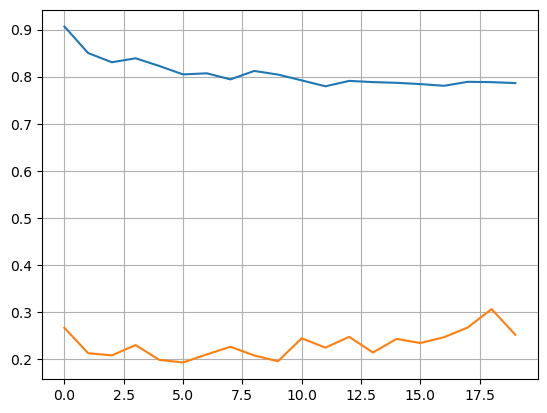

In [3]:
import matplotlib.pyplot as plt

import torch
import torch.utils.data as data
import torchvision.transforms.v2 as tfs
import torchvision
import torch.nn as nn
import torch.optim as optim
from tqdm import tqdm
from torchvision.datasets import ImageFolder


class RavelTransform(nn.Module):
    def forward(self, item):
        return item.ravel()


class DigitNN(nn.Module):
    def __init__(self, input_dim, num_hidden, output_dim):
        super().__init__()
        self.layer1 = nn.Linear(input_dim, num_hidden)
        self.layer2 = nn.Linear(num_hidden, output_dim)
        self.dropout_1 = nn.Dropout1d(0.3)

    def forward(self, x):
        x = self.layer1(x)
        x = nn.functional.relu(x)
        x = self.dropout_1(x)
        x = self.layer2(x)
        return x


model = DigitNN(28 * 28, 128, 10)

transforms = tfs.Compose([tfs.ToImage(),  tfs.Grayscale(),
                          tfs.ToDtype(torch.float32, scale=True),
                          RavelTransform(),
                          ])

dataset_mnist = torchvision.datasets.MNIST(r'C:\datasets\mnist', download=True, train=True, transform=transforms)
d_train, d_val = data.random_split(dataset_mnist, [0.7, 0.3])
train_data = data.DataLoader(d_train, batch_size=32, shuffle=True)
train_data_val = data.DataLoader(d_val, batch_size=32, shuffle=False)


optimizer = optim.Adam(params=model.parameters(), lr=0.01) # , weight_decay=0.001)
loss_function = nn.CrossEntropyLoss()
epochs = 20

loss_lst_val = [] # список значений потерь при валидации
loss_lst = [] # список значений потерь при обучении

for _e in range(epochs):
    model.train()
    loss_mean = 0
    lm_count = 0

    train_tqdm = tqdm(train_data, leave=False)
    for x_train, y_train in train_tqdm:
        predict = model(x_train)
        loss = loss_function(predict, y_train)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        lm_count += 1
        loss_mean = 1/lm_count * loss.item() + (1 - 1/lm_count) * loss_mean
        train_tqdm.set_description(f"Epoch [{_e+1}/{epochs}], loss_mean={loss_mean:.3f}")

    # валидация модели
    model.eval()
    Q_val = 0
    count_val = 0

    for x_val, y_val in train_data_val:
        with torch.no_grad():
            p = model(x_val)
            loss = loss_function(p, y_val)
            Q_val += loss.item()
            count_val += 1

    Q_val /= count_val

    loss_lst.append(loss_mean)
    loss_lst_val.append(Q_val)

    print(f" | loss_mean={loss_mean:.3f}, Q_val={Q_val:.3f}")

d_test = torchvision.datasets.MNIST(r'C:\datasets\mnist', download=True, train=False, transform=transforms)
test_data = data.DataLoader(d_test, batch_size=500, shuffle=False)

Q = 0

# тестирование обученной НС
model.eval()

for x_test, y_test in test_data:
    with torch.no_grad():
        p = model(x_test)
        p = torch.argmax(p, dim=1)
        Q += torch.sum(p == y_test).item()

Q /= len(d_test)
print(Q)

# вывод графиков
plt.plot(loss_lst)
plt.plot(loss_lst_val)
plt.grid()
plt.show()